# Neural-network classification

A classifier on the OARL encoder predicts mitochondrial perturbation from ODT.

The examples use the first control and the first ETC-treated tomogram in the
classification test manifest. These two samples illustrate inference; they do
not estimate performance on the full test set. Labels are **0 = control** and
**1 = ETC-perturbed**.

Install `requirements-notebooks.txt`, extract the classification dataset next to
`OARL/`, and place the downloaded weights in `checkpoints/` as described in the
[README](../README.md#data-and-model-weights). Set `DATA_DIR` below if needed.
The notebook runs on CPU or CUDA and reads ODT only.

In [1]:
from pathlib import Path
import csv
import sys

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import torch
from torch.utils.data import DataLoader

ROOT = Path(".") if Path("oarl_net").is_dir() else Path("..")
sys.path.insert(0, str(ROOT))
from oarl_net import Config, ODTDataset, create_model, load_tomograms
from oarl_net.checkpoint import load_weights

torch.set_num_threads(4)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = ROOT / ".." / "classification_dataset"
BATCH_SIZE = 3
print(f"Device: {DEVICE}")

Device: cpu


## Load two tomograms

Each tomogram supplies nine fixed 224 × 224 crops, each containing seven RI slices.

In [2]:
cfg = Config()
test_tomograms = load_tomograms(
    ROOT / "metadata/tomograms.csv", DATA_DIR, task="classification", split="test")
# The first test tomogram of each class in manifest order.
selected = [next(t for t in test_tomograms if t.label == label) for label in (0, 1)]
dataset = ODTDataset(selected, cfg.data, augment=False, use_subimages=True,
                     classification_only=True, in_memory=True)
loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
class_names = {0: "Control", 1: "ETC-perturbed"}
for t in selected:
    print(f"{t.id}: {t.chemical}; reference = {class_names[t.label]}")

Loading tomograms:   0%|          | 0/2 [00:00<?, ?it/s]

Loading tomograms:  50%|█████     | 1/2 [00:00<00:00,  2.28it/s]

Loading tomograms: 100%|██████████| 2/2 [00:00<00:00,  2.23it/s]

Loading tomograms: 100%|██████████| 2/2 [00:00<00:00,  2.24it/s]

odt_0610: Ctrl; reference = Control
odt_0656: Antimycin; reference = ETC-perturbed


## Predict from encoder features

The saved classifier outputs one probability per crop. A tomogram is classified as
ETC-perturbed when at least five crop probabilities exceed 0.5. The mean probability
is also retained as a continuous score.

In [3]:
from oarl_net.cls_trainer import predict

cfg.model.classification_mode = True
cfg.model.enable_heatmap_head = False
model = create_model(cfg.model)
load_weights(model, ROOT / "checkpoints/classification.pth")
model = model.to(DEVICE).eval()
probabilities, _ = predict(model, loader, DEVICE)
predictions = {key: int(np.count_nonzero(np.asarray(p) > 0.5) > len(p) / 2)
               for key, p in probabilities.items()}
del model
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

loaded 395 tensors from ../checkpoints/classification.pth (epoch 109)


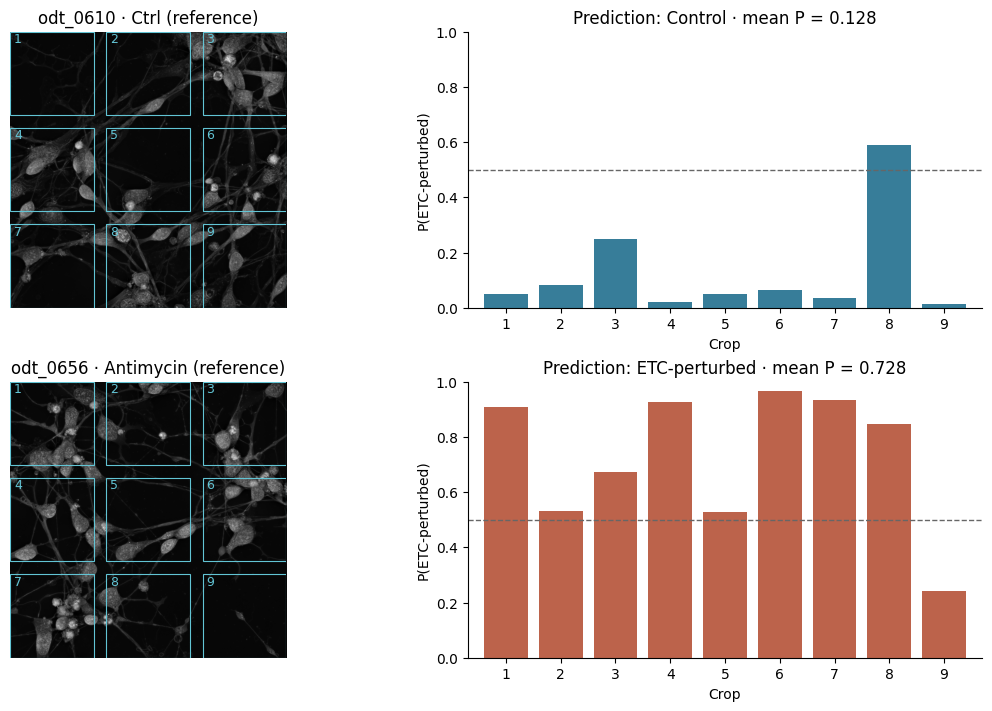

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
for row, tomogram in enumerate(selected):
    ax = axes[row, 0]
    ax.imshow(dataset.images[row].max(axis=2), cmap="gray", vmin=0, vmax=1)
    for crop, (y, x) in enumerate(dataset.subimage_positions):
        ax.add_patch(Rectangle((x, y), cfg.data.crop_size, cfg.data.crop_size,
                               fill=False, edgecolor="#62c4d4", linewidth=0.8))
        ax.text(x + 10, y + 28, str(crop + 1), color="#62c4d4", fontsize=9)
    ax.set_title(f"{tomogram.id} · {tomogram.chemical} (reference)")
    ax.axis("off")
    p = np.asarray(probabilities[tomogram.id])
    prediction = predictions[tomogram.id]
    ax = axes[row, 1]
    ax.bar(np.arange(1, 10), p, color="#bc634b" if prediction else "#377d99")
    ax.axhline(0.5, color="0.4", linestyle="--", linewidth=1)
    ax.set(xlim=(0.3, 9.7), ylim=(0, 1), xticks=range(1, 10),
           xlabel="Crop", ylabel="P(ETC-perturbed)",
           title=f"Prediction: {class_names[prediction]} · mean P = {p.mean():.3f}")
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

The left panels show normalized RI maximum projections and the nine crop positions.
The right panels show crop probabilities; dashed lines mark 0.5.

## Save predictions

In [5]:
output = ROOT / "predictions" / "neural_network"
output.mkdir(parents=True, exist_ok=True)
with (output / "predictions.csv").open("w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["tomogram", "chemical", "label", "prediction", "mean_probability",
                     "crop_probabilities"])
    for t in selected:
        p = np.asarray(probabilities[t.id])
        writer.writerow([t.id, t.chemical, t.label, predictions[t.id], float(p.mean()),
                         ";".join(f"{x:.8f}" for x in p)])
print(f"Saved {len(selected)} predictions to predictions/neural_network/predictions.csv")

Saved 2 predictions to predictions/neural_network/predictions.csv


For a larger batch, use `predict_classification.py`. The [logistic-regression
example](classification_logistic_regression.ipynb) classifies the same inputs from
organelle descriptors.